# Teste de Hipótese 

### Monstro: Beholder

Autor: **Carlos Gabriel de Oliveira Campos**

Professor: Dr. **Daniel Roberto Cassar**

Introdução (TODO)

___


## Contextualização

A confirmação da teoria da Relatividade Geral de Albert Einstein durante o eclipse 
solar de 1919 é um momento marcante na história da ciência. O experimento, conduzido 
por Sir Arthur Eddington, tinha como objetivo testar uma das principais previsões da 
Relatividade Geral: a curvatura da luz pela gravidade.
A Teoria Geral da Relatividade de Einstein, publicada em 1915, introduziu uma 
nova compreensão da gravidade. Em vez da visão clássica da gravidade como uma força, 
a teoria de Einstein propôs que objetos massivos, como o Sol, deformam o tecido do 
espaço‑tempo ao seu redor. A luz que passa perto de um objeto massivo destes seguiria 
um caminho curvo devido a essa distorção, criando o efeito de lente gravitacional.
A teoria de Einstein previu que, durante um eclipse solar, quando a massa do Sol 
bloqueasse a luz de estrelas distantes, as posições dessas estrelas pareceriam deslocadas 
devido ao campo gravitacional do Sol. As posições observadas das estrelas seriam 
diferentes de suas posições esperadas se a gravidade não afetasse a luz. Especificamente, 
as posições das estrelas seriam deslocadas para fora do Sol.
Os resultados esperados do experimento envolviam a medição do deslocamento 
angular das estrelas quando elas apareciam perto do Sol durante um eclipse solar total. 
O deslocamento angular seria a diferença entre a posição aparente de uma estrela e sua 
posição real na ausência da gravidade do Sol.
A teoria de Einstein previu que esse deslocamento angular seria de aproximadamente 
1.75 segundo de arco (arcseg) para estrelas que estivessem próximas ao Sol durante 
o eclipse.
Arthur Eddington organizou duas expedições (uma para Sobral, no Brasil, e outra 
para a Ilha do Príncipe, na África Ocidental) para observar o eclipse solar total de 29 
de maio de 1919. As equipes tiraram fotografias das estrelas que estavam próximas ao 
Sol durante o eclipse.
As fotografias tiradas durante o eclipse foram comparadas com fotografias do mesmo 
campo estelar tiradas quando o Sol não estava nas proximidades. As posições observadas 
das estrelas foram de fato deslocadas para fora do Sol, de acordo com as previsões de 
Einstein.

## Função de suporte 

Para plotar o histograma das medições simuladas de maneira mais informativa, fiz pequenas adaptações na função de suporte desenvolvida pelo professor Daniel, conforme [1].

In [18]:
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import seaborn as sns


def histograma_desloc(resultado, estatistica_observada):
    eixo = sns.histplot(
        resultado,
        stat="probability",
        bins=20,
    )

    cor_normal = eixo.patches[0].get_facecolor()
    cor_destaque = "orange"

    for barra in list(eixo.patches):
        x_esq = barra.get_x()
        x_dir = x_esq + barra.get_width()
        altura = barra.get_height()

        if x_dir <= estatistica_observada:
            pass

        elif x_esq >= estatistica_observada:
            barra.set_facecolor(cor_destaque)

        else:
            barra.set_width(estatistica_observada - x_esq)

            retangulo_laranja = plt.Rectangle(
                (estatistica_observada, 0),
                x_dir - estatistica_observada,
                altura,
                facecolor=cor_destaque,
                edgecolor=barra.get_edgecolor(),
                linewidth=barra.get_linewidth(),
            )
            eixo.add_patch(retangulo_laranja)

    eixo.axvline(estatistica_observada, color="red", linestyle="-")

    legendas = [
        mpatches.Patch(
            facecolor=cor_normal,
            label="Valores menores que a medida observada",
        ),
        mpatches.Patch(
            facecolor=cor_destaque,
            label="Valores maiores que a medida observada",
        ),
        mlines.Line2D(
            [], [], color="red", linestyle="-", label="Medida observada"
        ),
    ]

    # Altura baseada nas barras reais geradas
    altura_maxima = max(barra.get_height() for barra in eixo.patches)
    eixo.set_ylim(bottom=0, top=altura_maxima * 1.35)

    eixo.set(
        xlabel="Deslocamento angular simulado (arcseg)",
        ylabel="Probabilidade"
    )
    # loc="upper left" posiciona a legenda longe da linha em x = 1.98
    eixo.legend(handles=legendas, loc="upper left")

## Exercício

> Suponha que pelo modelo de Einstein e pelos equipamentos utilizados, o valor esperado para o deslocamento angular segue uma distribuição normal 𝒩︀(1.75,0.02) (isto é, tem média de 1.75 e variância de 0.02). Proponha e execute um teste de hipótese para testar o modelo de Einstein à luz do resultado obtido, usando de simulação, sabendo que **o deslocamento angular medido das estrelas durante o eclipse de 1919 
foi de aproximadamente 1.98 arcseg**.

Para este problema, podemos formular nossa **hipótese nula** $H_0$ de forma que o deslocamento angular segue a distribuição informada, ou seja, $X \sim \mathrm{Normal}(1.75,0.02)$. Ademais, será adotado um valor de 5% para a significância, uma vez que este é o padrão geral na ciência, e não há condições especiais particulares a essa questão para mudá-lo [2].  

In [19]:
SIGNIFICANCIA = 0.05

## Realizando a simulação

Vamos gerar uma simulação com 10 milhões de valores para o deslocamento angular, de modo que eles seguem a distribuição proposta.

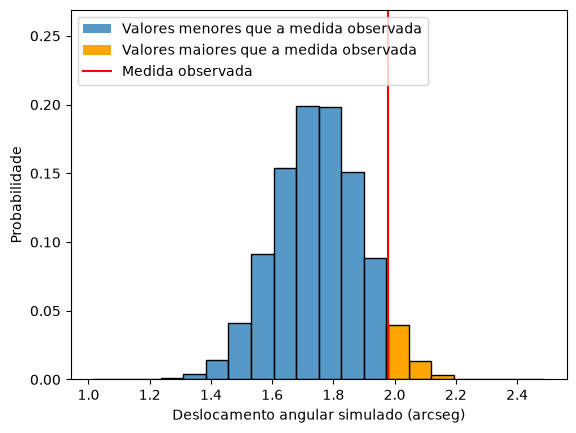

In [22]:
# Configurando semente aleatória
np.random.seed(42)

# Informações para a simulação
NUM_SIM = 10_000_000
VAL_CALC = 1.75
DESV_PADRAO = 0.02 ** (1/2)
VAL_MEDIDO = 1.98

# Gerando 1 milhão de valores
desloc_simulados = np.random.normal(loc=VAL_CALC, scale=DESV_PADRAO, size=NUM_SIM)

histograma_desloc(desloc_simulados, VAL_MEDIDO)

Vamos verificar as estatísticas da simulação

In [21]:
print(
    f"Média: {x.mean()}\n" +
    f"Variância: {x.var()}"
    )

Média: 1.7499909550413817
Variância: 0.020000543262427724


Como esperado de acordo com o Teorema do Limite Central, o grande volume da simulação nos proporcionou uma boa aproximação em relação à dsitribuição original. Assim, é razoável interpretá-la de modo que apresente, mesmo que aproximadamente, um eixo de simetria ao redor da média (1.75 arcseg).
 
Nesse caso, o valor medido de 1.98 arsecg foi de 0.23 arcseg maior do que a média, de acordo com $H_0$. A partir de sua simetria, podemos afirmar que essa medida está tão "distante" de $H_0$ como uma medida 0.23 arcseg *abaixo da média* (1.52 arcseg). Dessa maneira, o material em [1] nos auxiliar a compreender o cálculo do p-valor, definido como

$$
\textrm{p-valor} = P(X \leq 1.52 | H_0) + P(X \geq 1.98 | H_0)
$$

Se $H_0$ é verdadeira, então a variável $X$ deve serguir a **distribuição normal** com média em 1.75 e variância de 0.02:

$$
\textrm{p-valor} = P(X \geq 1.52 | X \sim \mathrm{Normal}(1.75,0.02)) + P(X \geq 1.98 | X \sim \mathrm{Normal}(1.75,0.02)).
$$

Uma forma de calcular estas probabilidades é pela cdf da distribuição Normal:


$$
P(X \leq 1.52 | X \sim \mathrm{Binomial}(1.75,0.02)) = F(1.52| 1.75, 0.02)
$$


$$
P(X \geq 1.98 | X \sim \mathrm{Normal}(1.75,0.02)) = 1 - F(1.98| 1.75, 0.02)
$$


Vamos calcular computacionalmente o p-valor:

In [27]:
contador = 0
for desloc in desloc_simulados:
    if 1.52 < desloc < 1.98:
        continue
    contador += 1
print(f"p-valor: {contador / NUM_SIM}")

p-valor: 0.1038591


## Conclusão

(TODO)

## Referências

[2] https://scienceinsights.org/what-percentage-is-statistically-significant-5-and-beyond/#:~:text=The%20standard%20threshold%20for%20statistical%20significance%20is%205%25%2C,is%20the%20most%20widely%20used%20convention%20in%20research.

[1] CASSAR, Daniel R. Material de aula **LMA-203 8.0 - Introdução aos testes de hipótese** para a disciplina de Estatística, 2026.


## Uso de IA neste trabalho

(todo)